In [1]:
import os

from tqdm import tqdm
import numpy as np
import matplotlib.pyplot as plt
import matplotlib 
import torch as th

from ml.loss import RMSELoss
from ml.data import add_feature_noise, add_label_noise

# Set matplotlib to use TeX for rendering
matplotlib.rcParams.update({"font.size": 16})
plt.rcParams["figure.dpi"] = 125 # set fig resolution

plt.rcParams.update({"text.usetex": True, "font.family": "Helvetica"})
seed = 42  # for reproducibility
np.random.seed(seed)

In [2]:
label_noise_std = 0.0
X_train = np.load("data/abc_non_lin_om_data/train/taus.npy")
print(X_train.shape)

y_train = -np.load("data/abc_non_lin_om_data/train/deltas.npy").reshape(-1, 1)

y_train = -add_label_noise(y_train, std=label_noise_std, seed=seed)

print("Label noise std:", label_noise_std)
print(y_train.shape)

abc_lib = np.column_stack((X_train, y_train))
print(f"ABC library array is of shape: {abc_lib.shape}. Note the last element of the 81 element rows are the true detuning.")

for i in range(X_train.shape[0]):
    assert y_train[i][0] == abc_lib[i, 80]
    # print(y_train[i][0])
    # print(abc_lib[i, -1])

(320000, 80)
Label noise std: 0.0
(320000, 1)
ABC library array is of shape: (320000, 81). Note the last element of the 81 element rows are the true detuning.


In [3]:
# def abc_algorithm(abc_dataset: np.ndarray[np.ndarray[float]], observed_data: np.ndarray[float], num_samples: int, epsilon: float):
#     rng = np.random.default_rng()
#     library_size = abc_dataset.shape[0]
#     # NOTE: The paper says to sample WITHOUT replacement
#     D_primes_idx = rng.choice(library_size, size=num_samples, replace=False)
#     D_primes = abc_dataset[D_primes_idx]
#     accepted_thetas = []
#     obs_counts, bin_edges = np.histogram(observed_data, bins=16) # from fig.9 in the paper they have 16 bins
#     for i in range(num_samples):
#         traj = D_primes[i, :80]
#         theta = D_primes[i, 80]
#         # the summary statistic used in the paper is the histogram of time delays
#         traj_counts, _ = np.histogram(traj, bins=16)
#         summary_stat_dist = np.linalg.norm(traj_counts - obs_counts)  # for non-linear regime they use the L2 norm
#         if summary_stat_dist <= epsilon:
#             accepted_thetas.append(theta)

#     return accepted_thetas 


def abc_algorithm_fast(
    abc_dataset: np.ndarray,
    observed_data: np.ndarray,
    num_samples: int,
    epsilon: float,
):
    rng = np.random.default_rng()
    library_size = abc_dataset.shape[0]

    # Sample without replacement
    idx = rng.choice(library_size, size=num_samples, replace=False)
    D = abc_dataset[idx]

    # Split trajectories and thetas
    trajs = D[:, :80]          # shape (num_samples, 80)
    thetas = D[:, 80]          # shape (num_samples,)

    # Compute observed histogram once
    obs_counts, bin_edges = np.histogram(observed_data, bins=16)

    # Use SAME bin edges for all trajectories
    # Digitize all values at once
    bin_indices = np.digitize(trajs, bin_edges[:-1], right=False)

    # Convert to one-hot counts per row
    traj_counts = np.zeros((num_samples, 16), dtype=int)
    rows = np.repeat(np.arange(num_samples), trajs.shape[1])
    cols = (bin_indices - 1).ravel()
    np.add.at(traj_counts, (rows, cols), 1)

    # Compute L2 distances in vectorized form
    dists = np.linalg.norm(traj_counts - obs_counts, axis=1)

    # Mask accepted
    accepted_thetas = thetas[dists <= epsilon]

    return accepted_thetas.tolist()

In [4]:
X_test = np.load("data/abc_non_lin_om_data/test/taus.npy")[:20000]
y_test = -np.load("data/abc_non_lin_om_data/test/deltas.npy")[:20000]

# mask = (y_test == -5.6) | (y_test == -2.8)
# # Use np.where() to get the indices where the mask is True
# # The PRApplied ABC paper considers only cases where \Delta=-5.6 or -2.8 see Figs. 8 and 10.
# indices = np.where(mask)
# X_test = X_test[indices]
# y_test = y_test[indices]

print(X_test.shape)
print(y_test.shape)

(20000, 80)
(20000,)


In [5]:
unique_values, counts = np.unique(y_test, return_counts=True)

counts_dict = dict(zip(unique_values, counts))

print(counts_dict)

{-10.0: 193, -9.9: 174, -9.8: 233, -9.7: 193, -9.6: 203, -9.5: 185, -9.4: 192, -9.3: 186, -9.2: 200, -9.1: 210, -9.0: 196, -8.9: 210, -8.8: 201, -8.7: 198, -8.6: 196, -8.5: 212, -8.4: 216, -8.3: 218, -8.2: 214, -8.1: 188, -8.0: 208, -7.9: 199, -7.8: 200, -7.7: 192, -7.6: 164, -7.5: 208, -7.4: 193, -7.3: 194, -7.2: 205, -7.1: 206, -7.0: 205, -6.9: 192, -6.8: 220, -6.7: 180, -6.6: 212, -6.5: 192, -6.4: 196, -6.3: 201, -6.2: 203, -6.1: 206, -6.0: 199, -5.9: 194, -5.8: 210, -5.7: 208, -5.6: 198, -5.5: 185, -5.4: 191, -5.3: 212, -5.2: 196, -5.1: 205, -5.0: 228, -4.9: 193, -4.8: 198, -4.7: 214, -4.6: 194, -4.5: 203, -4.4: 212, -4.3: 192, -4.2: 209, -4.1: 208, -4.0: 188, -3.9: 195, -3.8: 203, -3.7: 203, -3.6: 208, -3.5: 188, -3.4: 198, -3.3: 187, -3.2: 207, -3.1: 189, -3.0: 204, -2.9: 176, -2.8: 201, -2.7: 217, -2.6: 191, -2.5: 203, -2.4: 205, -2.3: 194, -2.2: 193, -2.1: 204, -2.0: 191, -1.9: 203, -1.8: 179, -1.7: 187, -1.6: 180, -1.5: 213, -1.4: 202, -1.3: 215, -1.2: 209, -1.1: 216, -1.0: 21

In [6]:
rmses = []
preds = []

for i in tqdm(range(X_test.shape[0])):
    true_theta = y_test[i]
    thetas = abc_algorithm_fast(abc_dataset=abc_lib, observed_data=X_test[i], num_samples=int(1e5), epsilon=9)
    if len(thetas) == 0:
        print(f"No samples were accepted for delta={true_theta}")
        continue

    preds.append(np.mean(thetas))

100%|██████████| 20000/20000 [1:47:43<00:00,  3.09it/s]  


In [7]:
rmse_loss = RMSELoss(reduction='none')
labels = th.tensor(y_test)
# print(labels.shape)

errors = rmse_loss(th.tensor(preds), labels).numpy().flatten()
# print(errors)

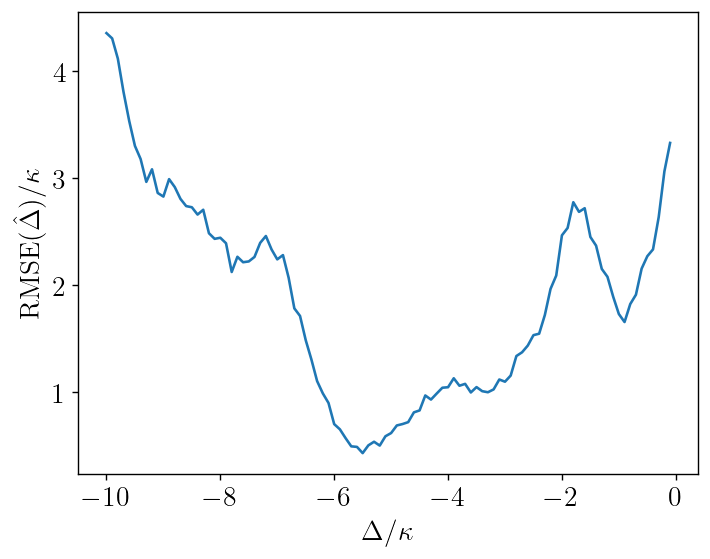

In [8]:
labels, inverse = np.unique(y_test, return_inverse=True)

sum_per_label = np.bincount(inverse, weights=errors)
count_per_label = np.bincount(inverse)

avg_rmse = sum_per_label / count_per_label

plt.figure()
plt.plot(labels, avg_rmse)
plt.xlabel(r"$\Delta/\kappa$")
plt.ylabel(r"$\textrm{RMSE}(\hat{\Delta})/\kappa$")
# plt.xlim(2.8, 5.6)
# plt.yscale('log')
plt.show()

In [9]:


os.makedirs("data/om_nonlin/abc/", exist_ok=True)
os.makedirs("data/om_nonlin/abc/", exist_ok=True)

np.save("data/om_nonlin/abc/deltas", labels)
np.save(f"data/om_nonlin/abc/rmses-label_noise-{label_noise_std}", avg_rmse)